In [1]:
#包和路径
from pathlib import Path
from datetime import datetime, timezone
import re
import traceback

import numpy as np
import pandas as pd
import h5py
import remfile

from dandi.dandiapi import DandiAPIClient
from pynwb import NWBHDF5IO
from tqdm import tqdm

PROJECT_ROOT = Path.cwd().parent

CANDIDATE_DIR = (
    PROJECT_ROOT
    / "results"
    / "candidate_sessions"
)

OUTPUT_ROOT = (
    PROJECT_ROOT
    / "results"
    / "prototype_sessions"
)

CACHE_DIR = (
    PROJECT_ROOT
    / "cache"
    / "remfile"
)

OUTPUT_ROOT.mkdir(
    parents=True,
    exist_ok=True,
)

CACHE_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

DANDISET_ID = "000409"
VERSION = "0.260309.1324"

In [2]:
#读取eligible sessions
ELIGIBLE_PATH = (
    CANDIDATE_DIR
    / "VISp_eligible_sessions.csv"
)

eligible_df = pd.read_csv(
    ELIGIBLE_PATH
)

print(
    "Eligible sessions:",
    len(eligible_df),
)

print(
    "Unique subjects:",
    eligible_df["subject"].nunique(),
)

display(
    eligible_df[
        [
            "subject",
            "session",
            "n_good_units_target_region",
            "n_valid_trials",
            "min_trials_across_conditions",
            "accuracy_valid",
        ]
    ].head(10)
)

Eligible sessions: 21
Unique subjects: 19


,subject,session,n_good_units_target_region,n_valid_trials,min_trials_across_conditions,accuracy_valid
0,CSH-ZAD-029,e349a2e7-50a3-47ca-bc45-20d1899854ec,40,883,106,0.906002
1,NR-0028,5c0c560e-9e1f-45e9-b66e-e4ee7855be84,36,843,98,0.836299
2,CSH-ZAD-025,90c61c38-b9fd-4cc3-9795-29160d2f8e55,20,656,62,0.835366
3,CSH-ZAD-025,6274dda8-3a59-4aa1-95f8-a8a549c46a26,62,590,61,0.903390
4,ibl-witten-29,58b1e920-cfc8-467e-b28b-7654a55d0977,24,565,52,0.907965
5,PL050,0cf6d255-8f2f-463e-84fb-c54bacb79f51,24,444,49,0.864865
6,ZFM-01577,09b2c4d1-058d-4c84-9fd4-97530f85baf6,51,424,46,0.830189
7,UCLA015,0c828385-6dd6-4842-a702-c5075f5f5e81,24,472,46,0.822034
8,CSHL052,85dc2ebd-8aaf-46b0-9284-a197aee8b16f,49,410,44,0.853659
9,NR-0021,e0928e11-2b86-4387-a203-80c77fab5d52,40,322,38,0.891304


In [3]:
#prototype session
PROTOTYPE_SESSION = (
    "e349a2e7-50a3-47ca-bc45-20d1899854ec"
)

prototype_matches = eligible_df.loc[
    eligible_df["session"]
    .astype(str)
    .eq(PROTOTYPE_SESSION)
].copy()

assert len(prototype_matches) == 1, (
    "Prototype session was not found uniquely "
    "in the eligible-session table."
)

prototype_row = prototype_matches.iloc[0]

SUBJECT = str(prototype_row["subject"])
SESSION = str(prototype_row["session"])
ASSET_PATH = str(prototype_row["asset_path"])

SESSION_OUTPUT_DIR = (
    OUTPUT_ROOT
    / SESSION
)

SESSION_OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

display(
    prototype_row[
        [
            "subject",
            "session",
            "asset_path",
            "n_good_units_target_region",
            "n_valid_trials",
            "n_high_left",
            "n_high_right",
            "n_low_left",
            "n_low_right",
        ]
    ]
)

subject                                                             CSH-ZAD-029
session                                    e349a2e7-50a3-47ca-bc45-20d1899854ec
asset_path                    sub-CSH-ZAD-029/sub-CSH-ZAD-029_ses-e349a2e7-5...
n_good_units_target_region                                                   40
n_valid_trials                                                              883
n_high_left                                                                 109
n_high_right                                                                106
n_low_left                                                                  211
n_low_right                                                                 177
Name: 0, dtype: object

In [4]:
# 定义远程打开 NWB
# 访问逻辑来自 02_global_session_inventory.ipynb，

def open_remote_nwb(
    asset_path,
    dandiset,
    cache_dir,
):
    """
    Open one remote NWB file through DANDI + remfile.

    Parameters
    ----------
    asset_path : str
        Path of the NWB asset within the Dandiset.

    dandiset
        DANDI dandiset object obtained from DandiAPIClient.

    cache_dir : pathlib.Path
        Local disk-cache directory.

    Returns
    -------
    rem_file
        Remote file object with local disk caching.

    h5py_file
        HDF5 file interface.

    io
        PyNWB input/output interface.

    nwbfile
        Loaded NWBFile object.
    """

    rem_file = None
    h5py_file = None
    io = None

    try:
        # 1. 根据 asset_path 找到 DANDI 里的文件
        asset = dandiset.get_asset_by_path(
            path=str(asset_path)
        )

        # 2. 获取实际的远程 S3 地址
        s3_url = asset.get_content_url(
            follow_redirects=1,
            strip_query=True,
        )

        # 3. 设置本地硬盘缓存
        disk_cache = remfile.DiskCache(
            str(cache_dir)
        )

        # 4. 建立支持远程按需读取的文件对象
        rem_file = remfile.File(
            s3_url,
            disk_cache=disk_cache,
        )

        # 5. 让 h5py 把远程文件作为 HDF5 打开
        h5py_file = h5py.File(
            rem_file,
            mode="r",
        )

        # 6. 用 PyNWB 读取 NWB 结构
        io = NWBHDF5IO(
            file=h5py_file,
            load_namespaces=True,
        )

        nwbfile = io.read()

        return (
            rem_file,
            h5py_file,
            io,
            nwbfile,
        )

    except Exception:
        # 如果打开过程在中途失败，
        # 关闭此前已经成功创建的资源。
        for obj in (
            io,
            h5py_file,
            rem_file,
        ):
            if obj is not None:
                try:
                    obj.close()
                except Exception:
                    pass

        raise

In [5]:
#打开
client = DandiAPIClient()

dandiset = client.get_dandiset(
    dandiset_id=DANDISET_ID,
    version_id=VERSION,
)

(
    rem_file,
    h5py_file,
    io,
    nwbfile,
) = open_remote_nwb(
    asset_path=ASSET_PATH,
    dandiset=dandiset,
    cache_dir=CACHE_DIR,
)

print("Opened subject:", SUBJECT)
print("Opened session:", SESSION)
print("NWB identifier:", nwbfile.identifier)

Opened subject: CSH-ZAD-029
Opened session: e349a2e7-50a3-47ca-bc45-20d1899854ec
NWB identifier: b49639d7-d472-4273-a550-b009481c8e28


In [6]:
#NWB基本结构
units_raw_df = (
    nwbfile.units
    .to_dataframe()
)

trials_raw_df = (
    nwbfile.trials
    .to_dataframe()
)

electrodes_raw_df = (
    nwbfile.electrodes
    .to_dataframe()
)

#规模
print(
    "Units:",
    units_raw_df.shape,
)

print(
    "Trials:",
    trials_raw_df.shape,
)

print(
    "Electrodes:",
    electrodes_raw_df.shape,
)

#列名
print("\nUnit columns:")
print(units_raw_df.columns.tolist())

print("\nTrial columns:")
print(trials_raw_df.columns.tolist())

print("\nElectrode columns:")
print(electrodes_raw_df.columns.tolist())

display(units_raw_df.head())
display(trials_raw_df.head())
display(electrodes_raw_df.head())

Units: (2377, 27)
Trials: (1022, 17)
Electrodes: (768, 18)

Unit columns:
['unit_name', 'rp_violation', 'presence_ratio_std', 'distance_from_probe_tip_um', 'spike_amplitudes_uV', 'cluster_uuid', 'spike_distances_from_probe_tip_um', 'waveform_mean', 'firing_rate', 'missed_spikes_estimate', 'probe_name', 'cumulative_drift_um_per_hour', 'electrodes', 'sliding_rp_violation', 'ibl_quality_score', 'noise_cutoff', 'kilosort2_label', 'presence_ratio', 'min_spike_amplitude_uV', 'max_spike_amplitude_uV', 'max_electrode', 'median_spike_amplitude_uV', 'spike_amplitude_std_dB', 'isi_violations_ratio', 'spike_count', 'peak_to_trough_duration_ms', 'spike_times']

Trial columns:
['start_time', 'stop_time', 'quiescence_period', 'gabor_stimulus_onset_time', 'auditory_cue_time', 'wheel_movement_onset_time', 'choice_registration_time', 'feedback_time', 'gabor_stimulus_offset_time', 'gabor_stimulus_contrast', 'gabor_stimulus_side', 'mouse_wheel_choice', 'is_mouse_rewarded', 'reward_volume_uL', 'probability

,unit_name,rp_violation,presence_ratio_std,distance_from_probe_tip_um,spike_amplitudes_uV,cluster_uuid,spike_distances_from_probe_tip_um,waveform_mean,firing_rate,missed_spikes_estimate,...,presence_ratio,min_spike_amplitude_uV,max_spike_amplitude_uV,max_electrode,median_spike_amplitude_uV,spike_amplitude_std_dB,isi_violations_ratio,spike_count,peak_to_trough_duration_ms,spike_times
id,,,,,,,,,,,,,,,,,,,,,
0,probe00_0,0.263176,51.658341,20.0,"[181.7334998785782, 134.88811714501594, 123.09...",70f70083-1c6e-47d2-b0c4-3d1346b65279,"[33.96317672729492, 49.969356536865234, 67.239...","[[1.2924693e-06, 8.5768625e-07, 3.8183116e-06,...",3.894915,0.5,...,0.882353,110.833083,356.832900,location \ id ...,137.984689,1.514303,0.353173,21811,0.333333,"[0.029546913007521592, 0.19031224558419993, 0...."
1,probe00_1,0.369389,28.148945,20.0,"[151.2316008555988, 145.2984787052582, 104.056...",10def196-a6f9-4750-9ceb-9aa915d81e9b,"[37.14346694946289, 60.3411750793457, 43.93286...","[[1.7027679e-07, 2.4157314e-06, 2.0022108e-07,...",3.046501,0.5,...,0.878788,103.515081,333.234756,location \ id ...,117.215049,1.238867,0.542861,17060,0.266667,"[0.2875447720461885, 1.2931364272759691, 1.965..."
2,probe00_2,1.771486,8.385791,20.0,"[138.8658262550166, 103.44132985872534, 124.34...",ca63f1ba-5b4d-4317-b09b-215df7d429a7,"[30.438968658447266, 54.144813537597656, 30.47...","[[5.443334e-06, 8.592881e-06, 3.941901e-06, 3....",0.473940,0.5,...,0.695187,96.354652,317.896515,location \ id ...,120.577534,1.611916,5.394751,2654,0.333333,"[0.4183436866285824, 1.3036696732005455, 2.456..."
3,probe00_3,0.828273,10.913507,20.0,"[124.57790066024968, 187.18964225045838, 175.4...",d1b44ce3-c553-4e5c-936b-f1d23b1f03d6,"[33.90117263793945, 39.29405975341797, 35.9614...","[[5.9752356e-06, 9.5117446e-07, 6.4613805e-06,...",0.708946,0.5,...,0.688057,111.237449,385.489069,location \ id ...,133.520938,1.512160,1.649613,3970,0.300000,"[1.0306052725229278, 2.3663275215406876, 2.404..."
4,probe00_4,0.316524,6.031597,20.0,"[96.5875949144106, 97.99086809825255, 120.7422...",ddcffcbc-3d69-48e7-b436-ba14951e9ecc,"[89.95680236816406, 77.51494598388672, 43.3975...","[[1.0219721e-05, 1.018421e-06, 1.0075648e-05, ...",0.373402,0.5,...,0.677362,96.292783,254.473620,location \ id ...,110.019765,1.360583,0.457416,2091,0.233333,"[10.347227959753734, 12.553442985101569, 12.94..."


,start_time,stop_time,quiescence_period,gabor_stimulus_onset_time,auditory_cue_time,wheel_movement_onset_time,choice_registration_time,feedback_time,gabor_stimulus_offset_time,gabor_stimulus_contrast,gabor_stimulus_side,mouse_wheel_choice,is_mouse_rewarded,reward_volume_uL,probability_left,block_type,block_index
id,,,,,,,,,,,,,,,,,
0,44.536379,46.967870,0.541949,45.167516,45.169949,45.307196,45.408875,45.408959,46.467819,100.0,right,counter_clockwise,True,1.5,0.5,unbiased,0
1,47.329567,50.850978,0.457997,48.799920,48.800986,48.892196,49.289472,49.289571,50.350864,25.0,left,clockwise,True,1.5,0.5,unbiased,0
2,51.218878,53.684192,0.426862,51.883111,51.885178,52.017196,52.115783,52.115888,53.184181,25.0,right,counter_clockwise,True,1.5,0.5,unbiased,0
3,54.061493,57.049487,0.423191,55.199480,55.202879,55.318196,55.487190,55.487284,56.549478,12.5,right,counter_clockwise,True,1.5,0.5,unbiased,0
4,57.482285,60.167411,0.501897,58.417391,58.420891,58.510196,58.610795,58.610905,59.667333,25.0,right,counter_clockwise,True,1.5,0.5,unbiased,0


,location,group,electrode_name,contact_shapes,channel_name,rel_x,rel_y,probe_name,contact_ids,shank_ids,adc_group,adc_sample_order,group_name,x,y,z,imp,filtering
id,,,,,,,,,,,,,,,,,,
0,Motor nucleus of trigeminal,Probe00 pynwb.ecephys.ElectrodeGroup at 0x2218...,e0,square,"AP0,LF0",16.0,0.0,Probe00,e0,,0,0,Probe00,10249.0,5161.0,4167.0,NaN,
1,Motor nucleus of trigeminal,Probe00 pynwb.ecephys.ElectrodeGroup at 0x2218...,e1,square,"AP1,LF1",48.0,0.0,Probe00,e1,,1,0,Probe00,10249.0,5161.0,4167.0,NaN,
2,Motor nucleus of trigeminal,Probe00 pynwb.ecephys.ElectrodeGroup at 0x2218...,e2,square,"AP2,LF2",0.0,20.0,Probe00,e2,,0,1,Probe00,10249.0,5140.0,4153.0,NaN,
3,Motor nucleus of trigeminal,Probe00 pynwb.ecephys.ElectrodeGroup at 0x2218...,e3,square,"AP3,LF3",32.0,20.0,Probe00,e3,,1,1,Probe00,10249.0,5140.0,4153.0,NaN,
4,Motor nucleus of trigeminal,Probe00 pynwb.ecephys.ElectrodeGroup at 0x2218...,e4,square,"AP4,LF4",16.0,40.0,Probe00,e4,,0,2,Probe00,10249.0,5120.0,4140.0,NaN,


In [11]:
# ============================================================
# 检查 Unit、Trial 和 Electrode 表的关键字段
#
# 目的：
# 1. 确认 probe 数量
# 2. 确认 unit QC 标签的实际写法
# 3. 确认 trial 中 left/right、choice、reward 的编码
# 4. 确认 max_electrode 能否映射到 electrode 表
# ============================================================

print("Unit index name:", units_raw_df.index.name)
print("Trial index name:", trials_raw_df.index.name)
print("Electrode index name:", electrodes_raw_df.index.name)


# ------------------------------------------------------------
# 1. 查看 probe 构成
# ------------------------------------------------------------

print("\nUnits per probe:")

display(
    units_raw_df[
        "probe_name"
    ].value_counts(
        dropna=False
    )
)

print("\nElectrodes per probe:")

display(
    electrodes_raw_df[
        "probe_name"
    ].value_counts(
        dropna=False
    )
)


# ------------------------------------------------------------
# 2. 查看 unit QC 标签
# ------------------------------------------------------------

print("\nIBL quality scores:")

display(
    units_raw_df[
        "ibl_quality_score"
    ].value_counts(
        dropna=False
    )
)

print("\nKilosort labels:")

display(
    units_raw_df[
        "kilosort2_label"
    ].value_counts(
        dropna=False
    )
)


# ------------------------------------------------------------
# 3. 查看 trial 条件的实际编码
# ------------------------------------------------------------

trial_label_columns = [
    "gabor_stimulus_contrast",
    "gabor_stimulus_side",
    "mouse_wheel_choice",
    "is_mouse_rewarded",
    "probability_left",
    "block_type",
]

for column in trial_label_columns:
    print(f"\n{column}:")

    display(
        trials_raw_df[column]
        .value_counts(
            dropna=False
        )
    )


# ------------------------------------------------------------
# 4. 检查关键时间列的缺失情况
# ------------------------------------------------------------

trial_time_columns = [
    "gabor_stimulus_onset_time",
    "wheel_movement_onset_time",
    "choice_registration_time",
    "feedback_time",
    "gabor_stimulus_offset_time",
]

timing_missing_df = pd.DataFrame(
    {
        "n_missing": (
            trials_raw_df[
                trial_time_columns
            ]
            .isna()
            .sum()
        ),
        "missing_fraction": (
            trials_raw_df[
                trial_time_columns
            ]
            .isna()
            .mean()
        ),
    }
)

display(timing_missing_df)


# ------------------------------------------------------------
# 5. 检查 max_electrode 是否对应 electrode index
# ------------------------------------------------------------

max_electrode_values = pd.to_numeric(
    units_raw_df[
        "max_electrode"
    ],
    errors="coerce",
)

non_missing_max_electrode = (
    max_electrode_values
    .dropna()
)

mapping_fraction = (
    non_missing_max_electrode
    .isin(electrodes_raw_df.index)
    .mean()
)

print(
    "\nUnits with non-missing max_electrode:",
    len(non_missing_max_electrode),
)

print(
    "Fraction mapping to electrode index:",
    mapping_fraction,
)


# ------------------------------------------------------------
# 6. 查看几行关键 unit 信息
# ------------------------------------------------------------

display(
    units_raw_df[
        [
            "unit_name",
            "probe_name",
            "max_electrode",
            "ibl_quality_score",
            "kilosort2_label",
            "firing_rate",
            "spike_count",
        ]
    ]
    .head(10)
)

Unit index name: id
Trial index name: id
Electrode index name: id

Units per probe:


probe_name
Probe00    1398
Probe01     979
Name: count, dtype: int64


Electrodes per probe:


probe_name
Probe00    384
Probe01    384
Name: count, dtype: int64


IBL quality scores:


ibl_quality_score
0.333333    1066
0.666667     620
0.000000     493
1.000000     198
Name: count, dtype: int64

... (13 outputs left out)

block_type
left_block     505
right_block    427
unbiased        90
Name: count, dtype: int64

,n_missing,missing_fraction
gabor_stimulus_onset_time,0,0.0
wheel_movement_onset_time,0,0.0
choice_registration_time,0,0.0
feedback_time,0,0.0
gabor_stimulus_offset_time,0,0.0



Units with non-missing max_electrode: 0
Fraction mapping to electrode index: nan


,unit_name,probe_name,max_electrode,ibl_quality_score,kilosort2_label,firing_rate,spike_count
id,,,,,,,
0,probe00_0,Probe00,location \ id ...,0.666667,mua,3.894915,21811
1,probe00_1,Probe00,location \ id ...,0.333333,mua,3.046501,17060
2,probe00_2,Probe00,location \ id ...,0.333333,mua,0.473940,2654
3,probe00_3,Probe00,location \ id ...,0.333333,mua,0.708946,3970
4,probe00_4,Probe00,location \ id ...,0.333333,mua,0.373402,2091
5,probe00_5,Probe00,location \ id ...,0.666667,good,17.047015,95461
6,probe00_6,Probe00,location \ id ...,1.000000,good,5.677636,31794
7,probe00_7,Probe00,location \ id ...,0.666667,good,4.639754,25982
8,probe00_8,Probe00,location \ id ...,0.666667,mua,8.292877,46439


In [12]:
# 查看第一个 unit 的 max_electrode 对象

sample_max_electrode = (
    units_raw_df["max_electrode"].iloc[0]
)

print(
    "Python type:",
    type(sample_max_electrode),
)

display(sample_max_electrode)

if isinstance(
    sample_max_electrode,
    pd.DataFrame,
):
    print(
        "Shape:",
        sample_max_electrode.shape,
    )

    print(
        "Index:",
        sample_max_electrode.index.tolist(),
    )

    print(
        "Columns:",
        sample_max_electrode.columns.tolist(),
    )

Python type: <class 'pandas.DataFrame'>


,location,group,electrode_name,contact_shapes,channel_name,rel_x,rel_y,probe_name,contact_ids,shank_ids,adc_group,adc_sample_order,group_name,x,y,z,imp,filtering
id,,,,,,,,,,,,,,,,,,
0,Motor nucleus of trigeminal,Probe00 pynwb.ecephys.ElectrodeGroup at 0x2218...,e0,square,"AP0,LF0",16.0,0.0,Probe00,e0,,0,0,Probe00,10249.0,5161.0,4167.0,NaN,


Shape: (1, 18)
Index: [0]
Columns: ['location', 'group', 'electrode_name', 'contact_shapes', 'channel_name', 'rel_x', 'rel_y', 'probe_name', 'contact_ids', 'shank_ids', 'adc_group', 'adc_sample_order', 'group_name', 'x', 'y', 'z', 'imp', 'filtering']


In [13]:
# ============================================================
# 从每个 unit 的 max_electrode 嵌套 DataFrame 中，
# 提取代表性 electrode 的 ID、脑区、probe 和坐标
# ============================================================

def extract_max_electrode_metadata(max_electrode_object):
    """
    从一个 unit 的 max_electrode 对象中提取
    代表性 electrode 的基本信息。
    """

    # 如果不是有效的一行 DataFrame，则返回缺失值
    if (
        not isinstance(max_electrode_object, pd.DataFrame)
        or max_electrode_object.empty
    ):
        return pd.Series(
            {
                "max_electrode_id": pd.NA,
                "region_raw": pd.NA,
                "max_electrode_probe_name": pd.NA,
                "electrode_x": np.nan,
                "electrode_y": np.nan,
                "electrode_z": np.nan,
            }
        )

    # 这张嵌套表正常情况下只有一行
    electrode_id = max_electrode_object.index[0]
    electrode_row = max_electrode_object.iloc[0]

    return pd.Series(
        {
            "max_electrode_id": electrode_id,
            "region_raw": electrode_row.get(
                "location",
                pd.NA,
            ),
            "max_electrode_probe_name": electrode_row.get(
                "probe_name",
                pd.NA,
            ),
            "electrode_x": electrode_row.get(
                "x",
                np.nan,
            ),
            "electrode_y": electrode_row.get(
                "y",
                np.nan,
            ),
            "electrode_z": electrode_row.get(
                "z",
                np.nan,
            ),
        }
    )


max_electrode_metadata_df = (
    units_raw_df["max_electrode"]
    .apply(extract_max_electrode_metadata)
)

display(
    max_electrode_metadata_df.head(10)
)

#验证
print(
    "Units with resolved max electrode:",
    int(
        max_electrode_metadata_df[
            "max_electrode_id"
        ]
        .notna()
        .sum()
    ),
)

print(
    "Units with region label:",
    int(
        max_electrode_metadata_df[
            "region_raw"
        ]
        .notna()
        .sum()
    ),
)

display(
    max_electrode_metadata_df[
        "region_raw"
    ]
    .value_counts(
        dropna=False
    )
    .head(20)
)

,max_electrode_id,region_raw,max_electrode_probe_name,electrode_x,electrode_y,electrode_z
id,,,,,,
0,0,Motor nucleus of trigeminal,Probe00,10249.0,5161.0,4167.0
1,0,Motor nucleus of trigeminal,Probe00,10249.0,5161.0,4167.0
2,0,Motor nucleus of trigeminal,Probe00,10249.0,5161.0,4167.0
3,0,Motor nucleus of trigeminal,Probe00,10249.0,5161.0,4167.0
4,0,Motor nucleus of trigeminal,Probe00,10249.0,5161.0,4167.0
5,1,Motor nucleus of trigeminal,Probe00,10249.0,5161.0,4167.0
6,1,Motor nucleus of trigeminal,Probe00,10249.0,5161.0,4167.0
7,1,Motor nucleus of trigeminal,Probe00,10249.0,5161.0,4167.0
8,1,Motor nucleus of trigeminal,Probe00,10249.0,5161.0,4167.0


Units with resolved max electrode: 2377
Units with region label: 2377


region_raw
Entorhinal area medial part dorsal zone layer 5      294
Supratrigeminal nucleus                              226
Motor nucleus of trigeminal                          220
Parabrachial nucleus                                 187
Primary visual area layer 5                          172
Entorhinal area medial part dorsal zone layer 2      160
Entorhinal area medial part dorsal zone layer 3      144
Primary visual area layer 1                          133
Cerebellum                                           105
Primary visual area layer 4                          101
lateral lemniscus                                     77
Primary visual area layer 2/3                         75
void                                                  67
Primary visual area layer 6a                          61
Posterolateral visual area layer 6a                   57
Retrosplenial area lateral agranular part layer 5     45
Retrosplenial area dorsal part layer 5                39
Midbrain            

In [14]:
#和electrode表比较
display(
    electrodes_raw_df.loc[[0]]
)

#unit的 max_electrode嵌套表 与 nwbfile.electrodes完整表 相互对应

,location,group,electrode_name,contact_shapes,channel_name,rel_x,rel_y,probe_name,contact_ids,shank_ids,adc_group,adc_sample_order,group_name,x,y,z,imp,filtering
id,,,,,,,,,,,,,,,,,,
0,Motor nucleus of trigeminal,Probe00 pynwb.ecephys.ElectrodeGroup at 0x2218...,e0,square,"AP0,LF0",16.0,0.0,Probe00,e0,,0,0,Probe00,10249.0,5161.0,4167.0,NaN,


In [15]:
unit_metadata_df = (
    units_raw_df
    .reset_index()
    .rename(
        columns={
            "id": "unit_index",
        }
    )
    [
        [
            "unit_index",
            "unit_name",
            "probe_name",
            "ibl_quality_score",
            "kilosort2_label",
            "firing_rate",
            "spike_count",
        ]
    ]
    .copy()
)

unit_metadata_df = pd.concat(
    [
        unit_metadata_df.reset_index(
            drop=True
        ),
        max_electrode_metadata_df.reset_index(
            drop=True
        ),
    ],
    axis=1,
)

display(
    unit_metadata_df.head()
)

,unit_index,unit_name,probe_name,ibl_quality_score,kilosort2_label,firing_rate,spike_count,max_electrode_id,region_raw,max_electrode_probe_name,electrode_x,electrode_y,electrode_z
0,0,probe00_0,Probe00,0.666667,mua,3.894915,21811,0,Motor nucleus of trigeminal,Probe00,10249.0,5161.0,4167.0
1,1,probe00_1,Probe00,0.333333,mua,3.046501,17060,0,Motor nucleus of trigeminal,Probe00,10249.0,5161.0,4167.0
2,2,probe00_2,Probe00,0.333333,mua,0.473940,2654,0,Motor nucleus of trigeminal,Probe00,10249.0,5161.0,4167.0
3,3,probe00_3,Probe00,0.333333,mua,0.708946,3970,0,Motor nucleus of trigeminal,Probe00,10249.0,5161.0,4167.0
4,4,probe00_4,Probe00,0.333333,mua,0.373402,2091,0,Motor nucleus of trigeminal,Probe00,10249.0,5161.0,4167.0


In [16]:
# 清理文本、合并皮层 layer，并建立 good-unit 标签
import re


def clean_text(value):
    """
    将文本统一转换为去除首尾空格的字符串。
    缺失值保留为 pd.NA。
    """
    if pd.isna(value):
        return pd.NA

    if isinstance(value, bytes):
        return (
            value
            .decode(
                "utf-8",
                errors="replace",
            )
            .strip()
        )

    return str(value).strip()


def collapse_cortical_layer(region_name):
    """
    删除脑区名称末尾的 cortical layer 后缀。

    例如：
    Primary visual area, layer 4
    → Primary visual area

    非皮层分层名称保持不变。
    """
    if pd.isna(region_name):
        return pd.NA

    region_name = str(region_name).strip()

    layer_pattern = (
        r",?\s+layer\s+"
        r"(?:2/3|6a|6b|1|2|3|4|5|6)$"
    )

    region_parent = re.sub(
        layer_pattern,
        "",
        region_name,
        flags=re.IGNORECASE,
    )

    return region_parent.strip()


# ------------------------------------------------------------
# 1. 清理文本列
# ------------------------------------------------------------

text_columns = [
    "unit_name",
    "probe_name",
    "kilosort2_label",
    "region_raw",
    "max_electrode_probe_name",
]

for column in text_columns:
    unit_metadata_df[column] = (
        unit_metadata_df[column]
        .apply(clean_text)
        .astype("string")
    )


# ------------------------------------------------------------
# 2. 建立不包含 layer 的 parent-region 名称
# ------------------------------------------------------------

unit_metadata_df["region_parent"] = (
    unit_metadata_df["region_raw"]
    .apply(collapse_cortical_layer)
    .astype("string")
)


# ------------------------------------------------------------
# 3. 将质量分数转成数值
# ------------------------------------------------------------

unit_metadata_df["ibl_quality_score"] = (
    pd.to_numeric(
        unit_metadata_df["ibl_quality_score"],
        errors="coerce",
    )
)


# ------------------------------------------------------------
# 4. 使用与 global inventory 完全相同的规则
# ------------------------------------------------------------

GOOD_UNIT_SCORE = 1.0

unit_metadata_df["is_good_unit"] = (
    unit_metadata_df["ibl_quality_score"]
    .eq(GOOD_UNIT_SCORE)
)


display(
    unit_metadata_df[
        [
            "unit_index",
            "unit_name",
            "probe_name",
            "max_electrode_id",
            "region_raw",
            "region_parent",
            "ibl_quality_score",
            "is_good_unit",
            "firing_rate",
        ]
    ].head(10)
)

,unit_index,unit_name,probe_name,max_electrode_id,region_raw,region_parent,ibl_quality_score,is_good_unit,firing_rate
0,0,probe00_0,Probe00,0,Motor nucleus of trigeminal,Motor nucleus of trigeminal,0.666667,False,3.894915
1,1,probe00_1,Probe00,0,Motor nucleus of trigeminal,Motor nucleus of trigeminal,0.333333,False,3.046501
2,2,probe00_2,Probe00,0,Motor nucleus of trigeminal,Motor nucleus of trigeminal,0.333333,False,0.473940
3,3,probe00_3,Probe00,0,Motor nucleus of trigeminal,Motor nucleus of trigeminal,0.333333,False,0.708946
4,4,probe00_4,Probe00,0,Motor nucleus of trigeminal,Motor nucleus of trigeminal,0.333333,False,0.373402
5,5,probe00_5,Probe00,1,Motor nucleus of trigeminal,Motor nucleus of trigeminal,0.666667,False,17.047015
6,6,probe00_6,Probe00,1,Motor nucleus of trigeminal,Motor nucleus of trigeminal,1.000000,True,5.677636
7,7,probe00_7,Probe00,1,Motor nucleus of trigeminal,Motor nucleus of trigeminal,0.666667,False,4.639754
8,8,probe00_8,Probe00,1,Motor nucleus of trigeminal,Motor nucleus of trigeminal,0.666667,False,8.292877
9,9,probe00_9,Probe00,1,Motor nucleus of trigeminal,Motor nucleus of trigeminal,0.333333,False,8.354664


In [17]:
# 检查 unit metadata 是否与 global inventory 一致

print(
    "Total units:",
    len(unit_metadata_df),
)

print(
    "Whole-session good units:",
    int(
        unit_metadata_df[
            "is_good_unit"
        ].sum()
    ),
)

print(
    "Units with max electrode:",
    int(
        unit_metadata_df[
            "max_electrode_id"
        ].notna()
        .sum()
    ),
)

print(
    "Units with region label:",
    int(
        unit_metadata_df[
            "region_raw"
        ].notna()
        .sum()
    ),
)


# 检查 unit probe 与 max-electrode probe 是否一致
probe_agreement = (
    unit_metadata_df["probe_name"]
    .eq(
        unit_metadata_df[
            "max_electrode_probe_name"
        ]
    )
)

print(
    "Probe-name agreement:",
    probe_agreement.mean(),
)

Total units: 2377
Whole-session good units: 198
Units with max electrode: 2377
Units with region label: 2377
Probe-name agreement: 1.0


In [18]:
#VISp good units
TARGET_REGION = "Primary visual area"

selected_units_df = (
    unit_metadata_df.loc[
        unit_metadata_df["is_good_unit"]
        & unit_metadata_df["region_parent"]
        .eq(TARGET_REGION)
    ]
    .copy()
    .sort_values("unit_index")
    .reset_index(drop=True)
)

print(
    "Selected VISp good units:",
    len(selected_units_df),
)

display(
    selected_units_df[
        [
            "unit_index",
            "unit_name",
            "probe_name",
            "max_electrode_id",
            "region_raw",
            "region_parent",
            "ibl_quality_score",
            "kilosort2_label",
            "firing_rate",
            "spike_count",
        ]
    ].head(20)
)

Selected VISp good units: 40


,unit_index,unit_name,probe_name,max_electrode_id,region_raw,region_parent,ibl_quality_score,kilosort2_label,firing_rate,spike_count
0,1017,probe00_1017,Probe00,311,Primary visual area layer 5,Primary visual area,1.0,good,2.774709,15538
1,1025,probe00_1025,Probe00,313,Primary visual area layer 5,Primary visual area,1.0,good,6.647123,37223
2,1122,probe00_1122,Probe00,332,Primary visual area layer 4,Primary visual area,1.0,mua,3.601693,20169
3,2019,probe01_621,Probe01,639,Primary visual area layer 6a,Primary visual area,1.0,good,28.564422,159957
4,2038,probe01_640,Probe01,651,Primary visual area layer 6a,Primary visual area,1.0,good,3.049357,17076
5,2041,probe01_643,Probe01,653,Primary visual area layer 6a,Primary visual area,1.0,good,1.984154,11111
6,2052,probe01_654,Probe01,658,Primary visual area layer 6a,Primary visual area,1.0,good,2.953284,16538
7,2053,probe01_655,Probe01,659,Primary visual area layer 6a,Primary visual area,1.0,good,2.342019,13115
8,2054,probe01_656,Probe01,659,Primary visual area layer 6a,Primary visual area,1.0,good,5.255302,29429
9,2057,probe01_659,Probe01,660,Primary visual area layer 6a,Primary visual area,1.0,good,3.480082,19488


In [19]:
#核对
expected_n_visp_good_units = int(
    prototype_row[
        "n_good_units_target_region"
    ]
)

actual_n_visp_good_units = len(
    selected_units_df
)

print(
    "Expected from candidate table:",
    expected_n_visp_good_units,
)

print(
    "Extracted from NWB:",
    actual_n_visp_good_units,
)

assert (
    actual_n_visp_good_units
    == expected_n_visp_good_units
), (
    "VISp good-unit count does not match "
    "the candidate-session inventory."
)

Expected from candidate table: 40
Extracted from NWB: 40


In [23]:
# 建立 trial-level metadata
# 每一行 = 一个原始 trial

trial_metadata_df = (
    trials_raw_df
    .reset_index()
    .rename(
        columns={
            "id": "trial_index",
        }
    )
    .copy()
)

print(
    "Trial metadata shape:",
    trial_metadata_df.shape,
)

display(
    trial_metadata_df.head()
)

Trial metadata shape: (1022, 18)


,trial_index,start_time,stop_time,quiescence_period,gabor_stimulus_onset_time,auditory_cue_time,wheel_movement_onset_time,choice_registration_time,feedback_time,gabor_stimulus_offset_time,gabor_stimulus_contrast,gabor_stimulus_side,mouse_wheel_choice,is_mouse_rewarded,reward_volume_uL,probability_left,block_type,block_index
0,0,44.536379,46.967870,0.541949,45.167516,45.169949,45.307196,45.408875,45.408959,46.467819,100.0,right,counter_clockwise,True,1.5,0.5,unbiased,0
1,1,47.329567,50.850978,0.457997,48.799920,48.800986,48.892196,49.289472,49.289571,50.350864,25.0,left,clockwise,True,1.5,0.5,unbiased,0
2,2,51.218878,53.684192,0.426862,51.883111,51.885178,52.017196,52.115783,52.115888,53.184181,25.0,right,counter_clockwise,True,1.5,0.5,unbiased,0
3,3,54.061493,57.049487,0.423191,55.199480,55.202879,55.318196,55.487190,55.487284,56.549478,12.5,right,counter_clockwise,True,1.5,0.5,unbiased,0
4,4,57.482285,60.167411,0.501897,58.417391,58.420891,58.510196,58.610795,58.610905,59.667333,25.0,right,counter_clockwise,True,1.5,0.5,unbiased,0


In [25]:
# 派生 trial timing 变量

# 从视觉刺激出现到轮子开始运动
trial_metadata_df["reaction_time_s"] = (
    trial_metadata_df[
        "wheel_movement_onset_time"
    ]
    - trial_metadata_df[
        "gabor_stimulus_onset_time"
    ]
)


# 从视觉刺激出现到 choice 被正式登记
trial_metadata_df[
    "choice_time_from_stimulus_s"
] = (
    trial_metadata_df[
        "choice_registration_time"
    ]
    - trial_metadata_df[
        "gabor_stimulus_onset_time"
    ]
)


# 从运动开始到 choice 登记
trial_metadata_df[
    "movement_to_choice_s"
] = (
    trial_metadata_df[
        "choice_registration_time"
    ]
    - trial_metadata_df[
        "wheel_movement_onset_time"
    ]
)


# Gabor 在屏幕上持续的时间
trial_metadata_df[
    "stimulus_duration_s"
] = (
    trial_metadata_df[
        "gabor_stimulus_offset_time"
    ]
    - trial_metadata_df[
        "gabor_stimulus_onset_time"
    ]
)

#分布
display(
    trial_metadata_df[
        [
            "reaction_time_s",
            "choice_time_from_stimulus_s",
            "movement_to_choice_s",
            "stimulus_duration_s",
        ]
    ]
    .describe()
    .T
)
#异常值
print(
    "Negative reaction times:",
    int(
        trial_metadata_df[
            "reaction_time_s"
        ]
        .lt(0)
        .sum()
    ),
)

print(
    "Missing reaction times:",
    int(
        trial_metadata_df[
            "reaction_time_s"
        ]
        .isna()
        .sum()
    ),
)

,count,mean,std,min,25%,50%,75%,max
reaction_time_s,1022.0,0.691205,1.428646,-0.390000,0.139714,0.172539,0.330702,17.597221
choice_time_from_stimulus_s,1022.0,0.933619,1.914250,0.083635,0.261660,0.326963,0.616327,32.822953
movement_to_choice_s,1022.0,0.242414,0.972777,0.069136,0.109261,0.128286,0.177054,21.071083
stimulus_duration_s,1022.0,2.158223,2.479477,1.150018,1.318118,1.401243,2.282972,48.432623


Negative reaction times: 10
Missing reaction times: 0


In [28]:
#检查负值
negative_rt_df = (
    trial_metadata_df.loc[
        trial_metadata_df[
            "reaction_time_s"
        ].lt(0),
        [
            "trial_index",
            "start_time",
            "quiescence_period",
            "auditory_cue_time",
            "gabor_stimulus_onset_time",
            "wheel_movement_onset_time",
            "choice_registration_time",
            "reaction_time_s",
            "gabor_stimulus_contrast",
            "gabor_stimulus_side",
            "mouse_wheel_choice",
            "is_mouse_rewarded",
        ],
    ]
    .copy()
    .sort_values(
        "reaction_time_s"
    )
)

display(negative_rt_df)

,trial_index,start_time,quiescence_period,auditory_cue_time,gabor_stimulus_onset_time,wheel_movement_onset_time,choice_registration_time,reaction_time_s,gabor_stimulus_contrast,gabor_stimulus_side,mouse_wheel_choice,is_mouse_rewarded
941,941,3754.109718,0.505194,3754.671462,3754.668196,3754.278196,3755.099925,-0.390000,12.50,right,counter_clockwise,True
417,417,1684.055711,0.611069,1686.625587,1686.620954,1686.541196,1686.923622,-0.079759,100.00,left,clockwise,True
997,997,4021.691357,0.444553,4022.197673,4022.196773,4022.125196,4022.373260,-0.071578,100.00,left,counter_clockwise,False
935,935,3729.141349,0.555686,3729.758620,3729.753221,3729.703196,3730.035557,-0.050025,6.25,right,counter_clockwise,True
337,337,1391.896296,0.606713,1392.564863,1392.560763,1392.532196,1392.644398,-0.028567,25.00,left,clockwise,True
916,916,3650.939636,0.683443,3652.905773,3652.904640,3652.879196,3653.117646,-0.025444,100.00,right,counter_clockwise,True
115,115,453.986930,0.553405,454.613001,454.610301,454.593196,454.897134,-0.017105,100.00,left,clockwise,True
710,710,2772.540552,0.629465,2773.223483,2773.220050,2773.207196,2773.340952,-0.012854,100.00,left,clockwise,True
985,985,3956.881772,0.556710,3957.504777,3957.499344,3957.487196,3957.860778,-0.012148,6.25,left,clockwise,True
435,435,1753.877361,0.521359,1754.555827,1754.554427,1754.553196,1754.769366,-0.001231,12.50,left,clockwise,True


In [29]:
MIN_RT_S = 0.08
MAX_RT_S = 2.00
REQUIRED_TRIAL_COLUMNS = [
    "gabor_stimulus_onset_time",
    "wheel_movement_onset_time",
    "choice_registration_time",
    "feedback_time",
    "mouse_wheel_choice",
    "probability_left",
    "is_mouse_rewarded",
]
# 使用与 global inventory 完全相同的规则定义 valid trials

# 1. 检查必要字段是否存在
missing_required_columns = [
    column
    for column in REQUIRED_TRIAL_COLUMNS
    if column not in trial_metadata_df.columns
]

assert not missing_required_columns, (
    "Missing required trial columns: "
    f"{missing_required_columns}"
)

# 2. 重新计算 reaction time
# 与 summarize_trials() 中的定义完全一致：
# 轮子运动开始时间 - Gabor 刺激出现时间
trial_metadata_df["reaction_time_s"] = (
    pd.to_numeric(
        trial_metadata_df[
            "wheel_movement_onset_time"
        ],
        errors="coerce",
    )
    - pd.to_numeric(
        trial_metadata_df[
            "gabor_stimulus_onset_time"
        ],
        errors="coerce",
    )
)


# 3. 必要字段全部非缺失
trial_metadata_df["has_required_events"] = (
    trial_metadata_df[
        REQUIRED_TRIAL_COLUMNS
    ]
    .notna()
    .all(axis=1)
)


# 4. Reaction time 必须在指定范围内
trial_metadata_df["rt_in_range"] = (
    trial_metadata_df[
        "reaction_time_s"
    ]
    .between(
        MIN_RT_S,
        MAX_RT_S,
        inclusive="both",
    )
)


# 5. 最终 valid-trial 标签
trial_metadata_df["is_valid_trial"] = (
    trial_metadata_df[
        "has_required_events"
    ]
    & trial_metadata_df[
        "rt_in_range"
    ]
)


# 6. 只为 valid trials 保留 valid_rt_s
trial_metadata_df["valid_rt_s"] = np.where(
    trial_metadata_df[
        "is_valid_trial"
    ],
    trial_metadata_df[
        "reaction_time_s"
    ],
    np.nan,
)


In [30]:
# 检查当前 trial-level 结果是否复现 global inventory
valid_trials_df = (
    trial_metadata_df.loc[
        trial_metadata_df[
            "is_valid_trial"
        ]
    ]
    .copy()
)


actual_n_valid = int(
    trial_metadata_df[
        "is_valid_trial"
    ].sum()
)

expected_n_valid = int(
    prototype_row[
        "n_valid_trials"
    ]
)


actual_valid_fraction = float(
    trial_metadata_df[
        "is_valid_trial"
    ].mean()
)

expected_valid_fraction = float(
    prototype_row[
        "valid_trial_fraction"
    ]
)


actual_median_rt = float(
    valid_trials_df[
        "reaction_time_s"
    ].median()
)

expected_median_rt = float(
    prototype_row[
        "median_rt_valid_s"
    ]
)


reward_numeric = pd.to_numeric(
    valid_trials_df[
        "is_mouse_rewarded"
    ],
    errors="coerce",
)

actual_accuracy = float(
    reward_numeric.mean()
)

expected_accuracy = float(
    prototype_row[
        "accuracy_valid"
    ]
)


print(
    "Valid trials:",
    actual_n_valid,
    "/ expected:",
    expected_n_valid,
)

print(
    "Valid fraction:",
    actual_valid_fraction,
    "/ expected:",
    expected_valid_fraction,
)

print(
    "Median valid RT:",
    actual_median_rt,
    "/ expected:",
    expected_median_rt,
)

print(
    "Valid-trial accuracy:",
    actual_accuracy,
    "/ expected:",
    expected_accuracy,
)

Valid trials: 883 / expected: 883
Valid fraction: 0.8639921722113503 / expected: 0.8639921722113503
Median valid RT: 0.16655471192643745 / expected: 0.1665547119264374
Valid-trial accuracy: 0.9060022650056625 / expected: 0.9060022650056624


In [31]:
#排除部分
print(
    "Missing required events:",
    int(
        (
            ~trial_metadata_df[
                "has_required_events"
            ]
        ).sum()
    ),
)

print(
    "RT out of range among complete trials:",
    int(
        (
            trial_metadata_df[
                "has_required_events"
            ]
            & ~trial_metadata_df[
                "rt_in_range"
            ]
        ).sum()
    ),
)

print(
    "Total invalid trials:",
    int(
        (
            ~trial_metadata_df[
                "is_valid_trial"
            ]
        ).sum()
    ),
)
trial_metadata_df["invalid_reason"] = np.select(
    [
        ~trial_metadata_df[
            "has_required_events"
        ],
        (
            trial_metadata_df[
                "has_required_events"
            ]
            & trial_metadata_df[
                "reaction_time_s"
            ].lt(MIN_RT_S)
        ),
        (
            trial_metadata_df[
                "has_required_events"
            ]
            & trial_metadata_df[
                "reaction_time_s"
            ].gt(MAX_RT_S)
        ),
    ],
    [
        "missing_required_event",
        "reaction_time_too_short",
        "reaction_time_too_long",
    ],
    default="valid",
)

display(
    trial_metadata_df[
        "invalid_reason"
    ].value_counts(
        dropna=False
    )
)

Missing required events: 0
RT out of range among complete trials: 139
Total invalid trials: 139


invalid_reason
valid                      883
reaction_time_too_long     116
reaction_time_too_short     23
Name: count, dtype: int64

In [41]:
# 建立用于 spike 提取和分箱的 valid-trial 表
# analysis_trials_df：
#   只保留通过 global inventory 规则的 883 个 valid trial

analysis_trials_df = (
    trial_metadata_df.loc[
        trial_metadata_df["is_valid_trial"]
    ]
    .copy()
    .sort_values("trial_index")
    .reset_index(drop=True)
)

print(
    "All trials:",
    len(trial_metadata_df),
)

print(
    "Valid trials for neural analysis:",
    len(analysis_trials_df),
)

assert len(analysis_trials_df) == 883


All trials: 1022
Valid trials for neural analysis: 883


In [42]:
#检查结构
contrast_side_counts = pd.crosstab(
    analysis_trials_df[
        "gabor_stimulus_contrast"
    ],
    analysis_trials_df[
        "gabor_stimulus_side"
    ],
    margins=True,
)

display(contrast_side_counts)

display(
    pd.crosstab(
        analysis_trials_df[
            "gabor_stimulus_contrast"
        ],
        analysis_trials_df[
            "is_mouse_rewarded"
        ],
        margins=True,
    )
)

display(
    pd.crosstab(
        analysis_trials_df[
            "gabor_stimulus_contrast"
        ],
        analysis_trials_df[
            "probability_left"
        ],
        margins=True,
    )
)

gabor_stimulus_side,left,right,All
gabor_stimulus_contrast,,,
0.0,38,58,96
6.25,106,91,197
12.5,105,86,191
25.0,101,83,184
100.0,109,106,215
All,459,424,883


is_mouse_rewarded,False,True,All
gabor_stimulus_contrast,,,
0.0,33,63,96
6.25,28,169,197
12.5,10,181,191
25.0,8,176,184
100.0,4,211,215
All,83,800,883


probability_left,0.2,0.5,0.8,All
gabor_stimulus_contrast,,,,
0.0,48,5,43,96
6.25,81,16,100,197
12.5,89,19,83,191
25.0,66,18,100,184
100.0,85,19,111,215
All,369,77,437,883


In [43]:
# 提取 selected VISp good units 的完整 spike times
# 每个元素是一名 unit 在整场 session 中的全部 spike time。

selected_unit_indices = (
    selected_units_df[
        "unit_index"
    ]
    .astype(int)
    .to_numpy()
)

selected_spike_times = []

for unit_index in selected_unit_indices:
    spike_times = np.asarray(
        units_raw_df.loc[
            unit_index,
            "spike_times",
        ],
        dtype=float,
    )

    selected_spike_times.append(
        spike_times
    )

print(
    "Selected units:",
    len(selected_unit_indices),
)

print(
    "Spike-time arrays extracted:",
    len(selected_spike_times),
)

print(
    "Spikes in first selected unit:",
    len(selected_spike_times[0]),
)

Selected units: 40
Spike-time arrays extracted: 40
Spikes in first selected unit: 15538


In [48]:
# 核对提取出的 spike 数是否与 NWB metadata 一致

actual_spike_counts = np.asarray(
    [
        len(spike_times)
        for spike_times
        in selected_spike_times
    ],
    dtype=int,
)

expected_spike_counts = (
    selected_units_df[
        "spike_count"
    ]
    .astype(int)
    .to_numpy()
)

spike_count_matches = (
    actual_spike_counts
    == expected_spike_counts
)

print(
    "Units with matching spike counts:",
    int(spike_count_matches.sum()),
    "/",
    len(spike_count_matches),
)

assert spike_count_matches.all()

print(
    "All selected-unit spike counts match NWB metadata."
)

Units with matching spike counts: 40 / 40
All selected-unit spike counts match NWB metadata.


In [49]:
# 保存

SESSION_OUTPUT_DIR = (
    OUTPUT_ROOT
    / SESSION
)

SESSION_OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

SELECTED_UNITS_PATH = (
    SESSION_OUTPUT_DIR
    / "selected_units.csv"
)

ALL_TRIALS_PATH = (
    SESSION_OUTPUT_DIR
    / "all_trials_metadata.csv"
)

VALID_TRIALS_PATH = (
    SESSION_OUTPUT_DIR
    / "valid_trials_metadata.csv"
)

SPIKE_TIMES_PATH = (
    SESSION_OUTPUT_DIR
    / "selected_unit_spike_times.npz"
)

selected_units_df.to_csv(
    SELECTED_UNITS_PATH,
    index=False,
)

trial_metadata_df.to_csv(
    ALL_TRIALS_PATH,
    index=False,
)

analysis_trials_df.to_csv(
    VALID_TRIALS_PATH,
    index=False,
)

np.savez_compressed(
    SPIKE_TIMES_PATH,
    unit_index=selected_unit_indices,
    spike_times=np.asarray(
        selected_spike_times,
        dtype=object,
    ),
)

print("Saved:", SELECTED_UNITS_PATH)
print("Saved:", ALL_TRIALS_PATH)
print("Saved:", VALID_TRIALS_PATH)
print("Saved:", SPIKE_TIMES_PATH)

Saved: D:\Ephys_analysis\ibl-population-dynamics\results\prototype_sessions\e349a2e7-50a3-47ca-bc45-20d1899854ec\selected_units.csv
Saved: D:\Ephys_analysis\ibl-population-dynamics\results\prototype_sessions\e349a2e7-50a3-47ca-bc45-20d1899854ec\all_trials_metadata.csv
Saved: D:\Ephys_analysis\ibl-population-dynamics\results\prototype_sessions\e349a2e7-50a3-47ca-bc45-20d1899854ec\valid_trials_metadata.csv
Saved: D:\Ephys_analysis\ibl-population-dynamics\results\prototype_sessions\e349a2e7-50a3-47ca-bc45-20d1899854ec\selected_unit_spike_times.npz


In [50]:
# Stimulus-aligned spike binning parameters

ALIGN_EVENT_COLUMN = "gabor_stimulus_onset_time"

TIME_START_S = -0.5
TIME_END_S = 1.0
BIN_SIZE_S = 0.02


# 总时间长度为 1.5 s
# 1.5 / 0.02 = 75 bins
N_TIME_BINS = int(
    round(
        (TIME_END_S - TIME_START_S)
        / BIN_SIZE_S
    )
)


# 使用 linspace 避免浮点数累积误差
time_bin_edges_s = np.linspace(
    TIME_START_S,
    TIME_END_S,
    N_TIME_BINS + 1,
)


# 每个 bin 的中心时间
time_bin_centers_s = (
    time_bin_edges_s[:-1]
    + time_bin_edges_s[1:]
) / 2


print(
    "Alignment event:",
    ALIGN_EVENT_COLUMN,
)

print(
    "Time window:",
    TIME_START_S,
    "to",
    TIME_END_S,
    "s",
)

print(
    "Bin size:",
    BIN_SIZE_S,
    "s",
)

print(
    "Number of bins:",
    N_TIME_BINS,
)

print(
    "First five bin centers:",
    time_bin_centers_s[:5],
)

print(
    "Last five bin centers:",
    time_bin_centers_s[-5:],
)

Alignment event: gabor_stimulus_onset_time
Time window: -0.5 to 1.0 s
Bin size: 0.02 s
Number of bins: 75
First five bin centers: [-0.49 -0.47 -0.45 -0.43 -0.41]
Last five bin centers: [0.91 0.93 0.95 0.97 0.99]


In [51]:
# Prepare trial alignment times and output array

alignment_times_s = pd.to_numeric(
    analysis_trials_df[
        ALIGN_EVENT_COLUMN
    ],
    errors="coerce",
).to_numpy(dtype=float)


selected_unit_indices = (
    selected_units_df[
        "unit_index"
    ]
    .astype(int)
    .to_numpy()
)


N_TRIALS = len(
    analysis_trials_df
)

N_UNITS = len(
    selected_units_df
)


assert np.isfinite(
    alignment_times_s
).all(), (
    "Some valid trials have missing "
    "stimulus onset times."
)

assert len(
    selected_spike_times
) == N_UNITS


# 使用整数保存每个 bin 中的 spike 数
spike_counts = np.zeros(
    (
        N_TRIALS,
        N_UNITS,
        N_TIME_BINS,
    ),
    dtype=np.int16,
)


print(
    "Trials:",
    N_TRIALS,
)

print(
    "Units:",
    N_UNITS,
)

print(
    "Time bins:",
    N_TIME_BINS,
)

print(
    "Target shape:",
    spike_counts.shape,
)

Trials: 883
Units: 40
Time bins: 75
Target shape: (883, 40, 75)


In [52]:
# Bin spike times relative to Gabor stimulus onset
# spike_counts[trial, unit, time_bin]
# 当前 trial、当前 unit、当前时间 bin 中的 spike 数

for trial_position, alignment_time_s in enumerate(
    alignment_times_s
):

    # 将相对于 stimulus onset 的 bin edges
    # 转换为整场 session 中的绝对时间
    absolute_bin_edges_s = (
        alignment_time_s
        + time_bin_edges_s
    )

    for unit_position, spike_times_s in enumerate(
        selected_spike_times
    ):

        spike_times_s = np.asarray(
            spike_times_s,
            dtype=float,
        )

        counts, _ = np.histogram(
            spike_times_s,
            bins=absolute_bin_edges_s,
        )

        spike_counts[
            trial_position,
            unit_position,
            :,
        ] = counts


print(
    "Binning finished."
)

print(
    "spike_counts shape:",
    spike_counts.shape,
)

print(
    "spike_counts dtype:",
    spike_counts.dtype,
)

print(
    "Total spikes inside all trial windows:",
    int(spike_counts.sum()),
)

Binning finished.
spike_counts shape: (883, 40, 75)
spike_counts dtype: int16
Total spikes inside all trial windows: 304541


In [53]:
# Basic binning QC

assert spike_counts.shape == (
    883,
    40,
    75,
)

assert np.issubdtype(
    spike_counts.dtype,
    np.integer,
)

assert (
    spike_counts >= 0
).all()

print(
    "Maximum spike count in one 20-ms bin:",
    int(spike_counts.max()),
)

print(
    "Fraction of bins containing zero spikes:",
    float(
        (
            spike_counts == 0
        ).mean()
    ),
)

print(
    "Fraction of bins containing at least one spike:",
    float(
        (
            spike_counts > 0
        ).mean()
    ),
)

Maximum spike count in one 20-ms bin: 8
Fraction of bins containing zero spikes: 0.9068335220838052
Fraction of bins containing at least one spike: 0.09316647791619478


In [54]:
# Independently verify several trial-unit combinations

rng = np.random.default_rng(
    42
)

test_trial_positions = rng.choice(
    N_TRIALS,
    size=5,
    replace=False,
)

test_unit_positions = rng.choice(
    N_UNITS,
    size=5,
    replace=False,
)


for trial_position, unit_position in zip(
    test_trial_positions,
    test_unit_positions,
):

    alignment_time_s = (
        alignment_times_s[
            trial_position
        ]
    )

    window_start_s = (
        alignment_time_s
        + TIME_START_S
    )

    window_end_s = (
        alignment_time_s
        + TIME_END_S
    )

    spike_times_s = np.asarray(
        selected_spike_times[
            unit_position
        ],
        dtype=float,
    )

    left_index = np.searchsorted(
        spike_times_s,
        window_start_s,
        side="left",
    )

    right_index = np.searchsorted(
        spike_times_s,
        window_end_s,
        side="right",
    )

    direct_count = (
        right_index
        - left_index
    )

    binned_count = int(
        spike_counts[
            trial_position,
            unit_position,
            :,
        ].sum()
    )

    print(
        f"trial={trial_position}, "
        f"unit={unit_position}, "
        f"direct={direct_count}, "
        f"binned={binned_count}"
    )

#核对
for trial_position, unit_position in zip(
    test_trial_positions,
    test_unit_positions,
):

    alignment_time_s = (
        alignment_times_s[
            trial_position
        ]
    )

    spike_times_s = np.asarray(
        selected_spike_times[
            unit_position
        ],
        dtype=float,
    )

    direct_count = int(
        (
            (
                spike_times_s
                >= (
                    alignment_time_s
                    + TIME_START_S
                )
            )
            & (
                spike_times_s
                <= (
                    alignment_time_s
                    + TIME_END_S
                )
            )
        ).sum()
    )

    binned_count = int(
        spike_counts[
            trial_position,
            unit_position,
            :,
        ].sum()
    )

    assert (
        direct_count
        == binned_count
    )

print(
    "Independent spike-count checks passed."
)

trial=681, unit=37, direct=4, binned=4
trial=387, unit=3, direct=1, binned=1
trial=576, unit=19, direct=43, binned=43
trial=78, unit=30, direct=0, binned=0
trial=382, unit=28, direct=3, binned=3
Independent spike-count checks passed.


In [55]:
# Convert binned spike counts to firing rate

firing_rates_hz = (
    spike_counts.astype(
        np.float32
    )
    / BIN_SIZE_S
)


print(
    "Firing-rate array shape:",
    firing_rates_hz.shape,
)

print(
    "Firing-rate dtype:",
    firing_rates_hz.dtype,
)

print(
    "Possible values in individual bins:",
    np.unique(
        firing_rates_hz
    )[:10],
)

Firing-rate array shape: (883, 40, 75)
Firing-rate dtype: float32
Possible values in individual bins: [  0.  50. 100. 150. 200. 250. 300. 350. 400.]


In [56]:
# baseline和刺激后

baseline_mask = (
    time_bin_centers_s >= -0.5
) & (
    time_bin_centers_s < 0.0
)

post_stimulus_mask = (
    time_bin_centers_s >= 0.0
) & (
    time_bin_centers_s < 0.5
)


mean_baseline_rate_hz = float(
    firing_rates_hz[
        :,
        :,
        baseline_mask,
    ].mean()
)

mean_post_stimulus_rate_hz = float(
    firing_rates_hz[
        :,
        :,
        post_stimulus_mask,
    ].mean()
)


print(
    "Mean population baseline rate:",
    mean_baseline_rate_hz,
    "Hz",
)

print(
    "Mean population 0–0.5 s rate:",
    mean_post_stimulus_rate_hz,
    "Hz",
)

Mean population baseline rate: 4.854133605957031 Hz
Mean population 0–0.5 s rate: 5.875368118286133 Hz


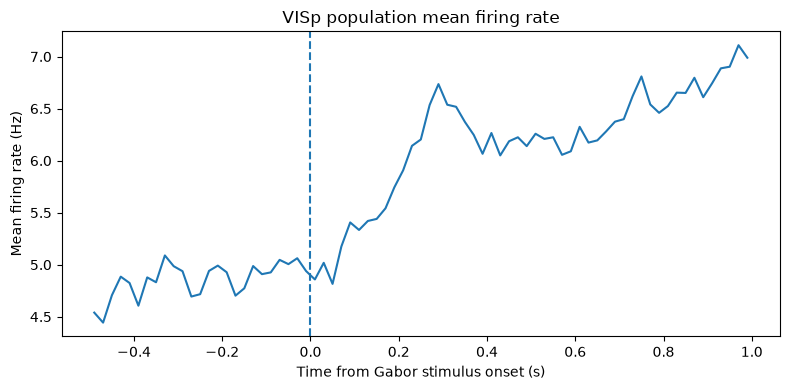

In [57]:
# Plot mean firing rate across all valid trials and VISp units

import matplotlib.pyplot as plt


population_mean_rate_hz = (
    firing_rates_hz.mean(
        axis=(0, 1)
    )
)


plt.figure(
    figsize=(8, 4)
)

plt.plot(
    time_bin_centers_s,
    population_mean_rate_hz,
)

plt.axvline(
    0,
    linestyle="--",
)

plt.xlabel(
    "Time from Gabor stimulus onset (s)"
)

plt.ylabel(
    "Mean firing rate (Hz)"
)

plt.title(
    "VISp population mean firing rate"
)

plt.tight_layout()
plt.show()

In [58]:
# Save stimulus-aligned binned spike data

BINNED_SPIKES_PATH = (
    SESSION_OUTPUT_DIR
    / "stimulus_aligned_spike_counts.npz"
)


np.savez_compressed(
    BINNED_SPIKES_PATH,

    # 主要数据
    spike_counts=spike_counts,

    # 时间信息
    time_bin_edges_s=time_bin_edges_s,
    time_bin_centers_s=time_bin_centers_s,

    # 保证 trial 和 unit 顺序可以还原
    trial_index=(
        analysis_trials_df[
            "trial_index"
        ]
        .astype(int)
        .to_numpy()
    ),
    unit_index=selected_unit_indices,

    # 分箱参数
    alignment_event=np.asarray(
        ALIGN_EVENT_COLUMN
    ),
    time_start_s=np.asarray(
        TIME_START_S
    ),
    time_end_s=np.asarray(
        TIME_END_S
    ),
    bin_size_s=np.asarray(
        BIN_SIZE_S
    ),
)


print(
    "Saved:",
    BINNED_SPIKES_PATH,
)

Saved: D:\Ephys_analysis\ibl-population-dynamics\results\prototype_sessions\e349a2e7-50a3-47ca-bc45-20d1899854ec\stimulus_aligned_spike_counts.npz


In [59]:
# Reload saved binned data and verify

loaded_binned_data = np.load(
    BINNED_SPIKES_PATH,
    allow_pickle=False,
)


loaded_spike_counts = (
    loaded_binned_data[
        "spike_counts"
    ]
)

loaded_time_centers_s = (
    loaded_binned_data[
        "time_bin_centers_s"
    ]
)

loaded_trial_indices = (
    loaded_binned_data[
        "trial_index"
    ]
)

loaded_unit_indices = (
    loaded_binned_data[
        "unit_index"
    ]
)


assert np.array_equal(
    loaded_spike_counts,
    spike_counts,
)

assert np.allclose(
    loaded_time_centers_s,
    time_bin_centers_s,
)

assert np.array_equal(
    loaded_trial_indices,
    analysis_trials_df[
        "trial_index"
    ].astype(int).to_numpy(),
)

assert np.array_equal(
    loaded_unit_indices,
    selected_unit_indices,
)


print(
    "Reload verification passed."
)

print(
    "Loaded shape:",
    loaded_spike_counts.shape,
)

Reload verification passed.
Loaded shape: (883, 40, 75)


In [62]:
# Close remote NWB resources

io.close()
h5py_file.close()
rem_file.close()

print(
    "Remote NWB resources closed."
)

Remote NWB resources closed.
